# **Irisデータセットの準備**

Irisデータセットには、150個のIrisの花に対して、4つの特徴量
*   花弁の長さ(petal length)
*   花弁の幅(petal width)
*   がくの長さ(sepal length)
*   がくの幅(sepal width)

の測定結果およびその花が三種類（setosa, versicolor, virginica）のIrisのどれかが入っている。


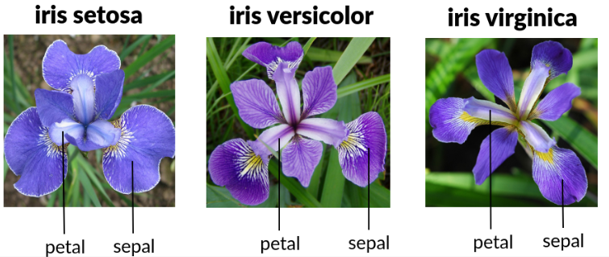

In [1]:
# 必要ライブラリーの読み込み
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Irisデータセットをダウンロード
import seaborn as sns
df = sns.load_dataset("iris")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


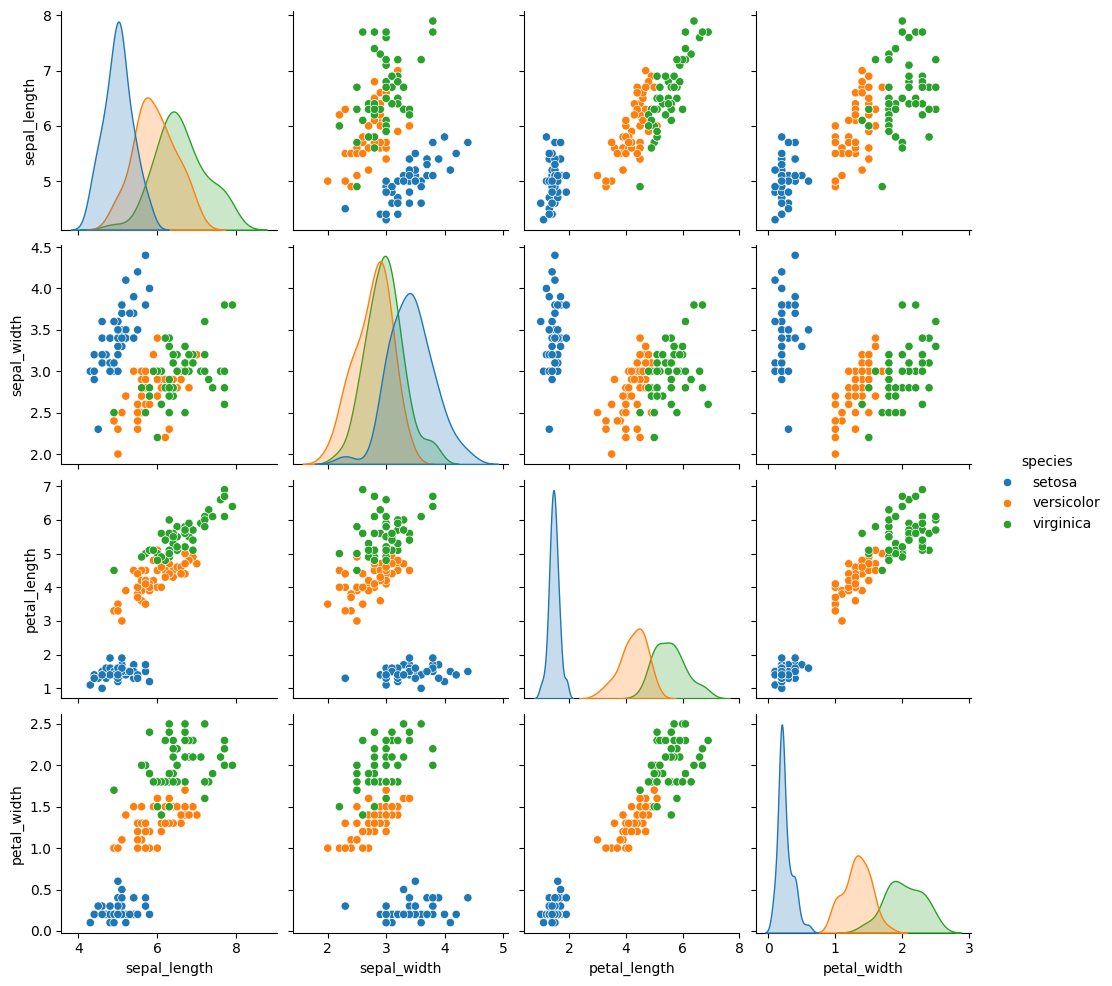

In [3]:
# 各特徴量の分布と相関の表示
sns.pairplot(df, hue = "species")



---



# **決定木（Decicion Tree）を用いた分類**

In [4]:
# 必要ライブラリーの読み込み
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [5]:
# 特徴量 (X) と 正解ラベル (y)　に分離
X = df.drop(columns=["species"], axis = 1)
y = df["species"]
#print(X.head())
#print(y.head())

In [6]:
# 全データを学習データとテストデータに７：３で分割
# さらに、順番をランダムにシャッフル
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=43)
#print(X_train, y_train)
#print(X_test, y_test)

In [7]:
# 学習データを用いて決定木を学習
dt_model = DecisionTreeClassifier(random_state=0)
dt_model.fit(X_train, y_train)

# 学習済み決定木の予測性能をテストデータで検証
y_pred = dt_model.predict(X_test)

In [8]:
accuracy_score_dt = accuracy_score(y_test, y_pred)
print("Accuracy score : ", accuracy_score_dt)
print("Criterion used: ", dt_model.criterion)

Accuracy score :  0.9333333333333333
Criterion used:  gini


In [9]:
# 交差検証を用いて性能評価
from sklearn.model_selection import cross_val_score
cv_accuracy_scores = cross_val_score(estimator=dt_model, X=X_train, y=y_train, cv=10)
cv_accuracy_scores_dt = cv_accuracy_scores.mean()
print("Mean of Accuracy score : ", cv_accuracy_scores_dt)

Mean of Accuracy score :  0.8945454545454548


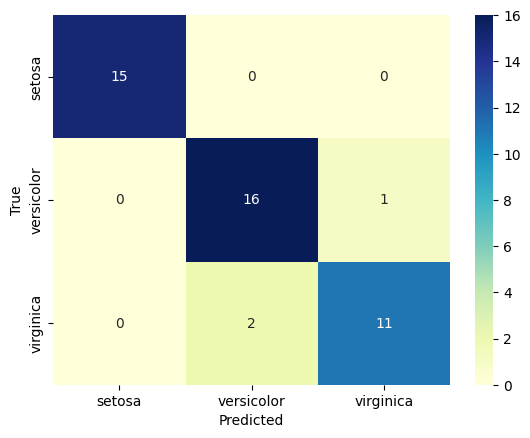

In [10]:
# 混同行列の計算
cnf_matrix = confusion_matrix(y_test, y_pred)
targets = ["setosa", "versicolor", "virginica"]
sns.heatmap(cnf_matrix, annot=True, cmap='YlGnBu',xticklabels=targets, yticklabels=targets)
plt.ylabel("True")
plt.xlabel("Predicted")
plt.show()

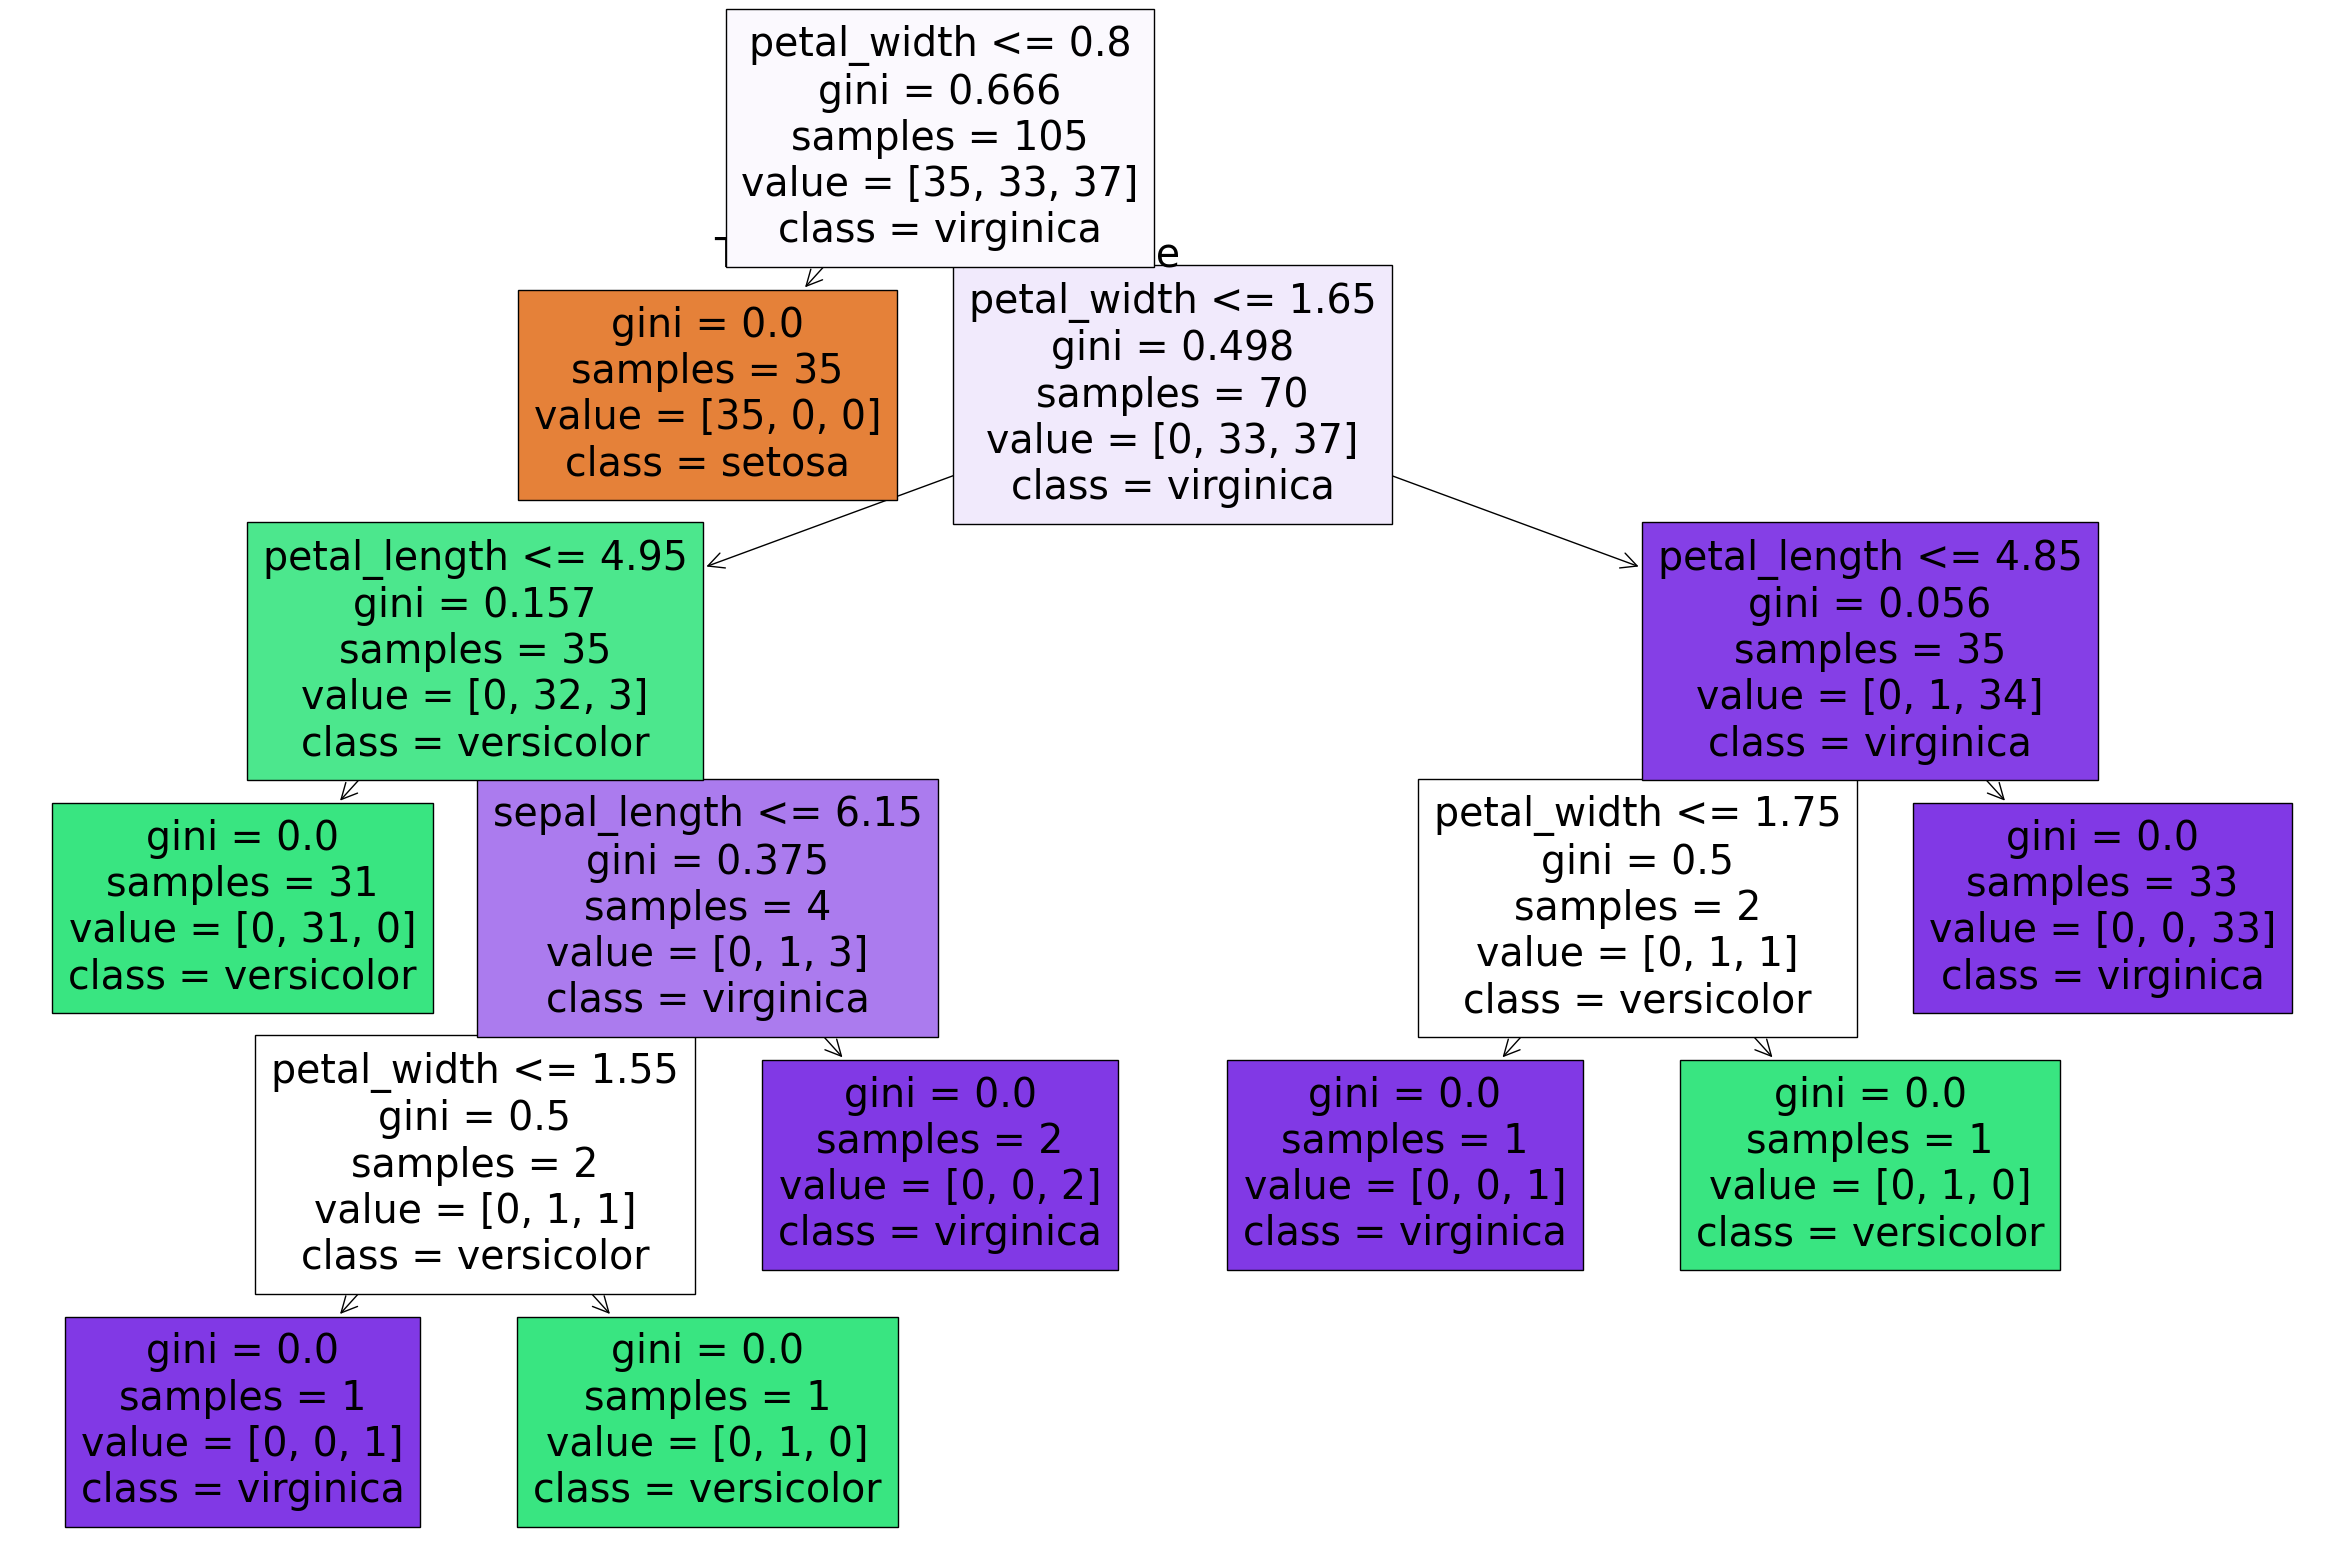

In [11]:
# 決定木の表示
from sklearn import tree
features = list(df.columns[:-1])
plt.figure(figsize = (30, 20))
tree_viz = tree.plot_tree(dt_model, filled=True, feature_names=features, class_names=targets)



---



# **ランダムフォレスト(Random Forest)を用いた分類**

In [12]:
from sklearn.ensemble import RandomForestClassifier

# 学習データを用いてランダムフォレストを学習
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)

# 学習したランダムフォレストの予測性能をテストデータで検証
y_pred = rf_model.predict(X_test)

accuracy_score_rf = accuracy_score(y_test, y_pred)
print("Accuracy score : ", accuracy_score_rf)
print("n_estimators used: ", rf_model.n_estimators)

Accuracy score :  0.9555555555555556
n_estimators used:  100


In [13]:
# 交差検証を用いて性能評価
cv_accuracy_scores = cross_val_score(estimator=rf_model, X=X_train, y=y_train, cv=10)
cv_accuracy_scores_rf = cv_accuracy_scores.mean()
print("Mean of Accuracy score : ", cv_accuracy_scores_rf)

Mean of Accuracy score :  0.9336363636363636


Text(0.5, 23.52222222222222, 'Predicted Label')

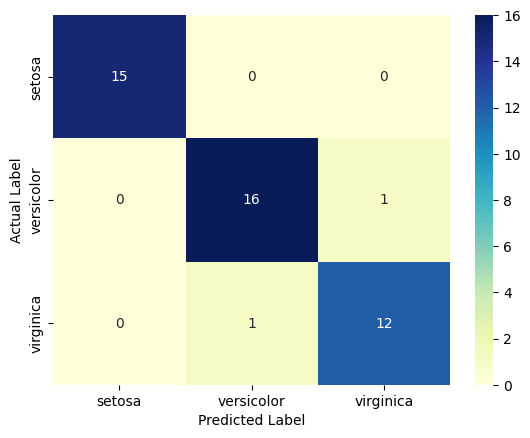

In [14]:
# 混同行列の計算
rf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(rf_matrix, annot=True, cmap='YlGnBu',xticklabels=targets, yticklabels=targets)
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")

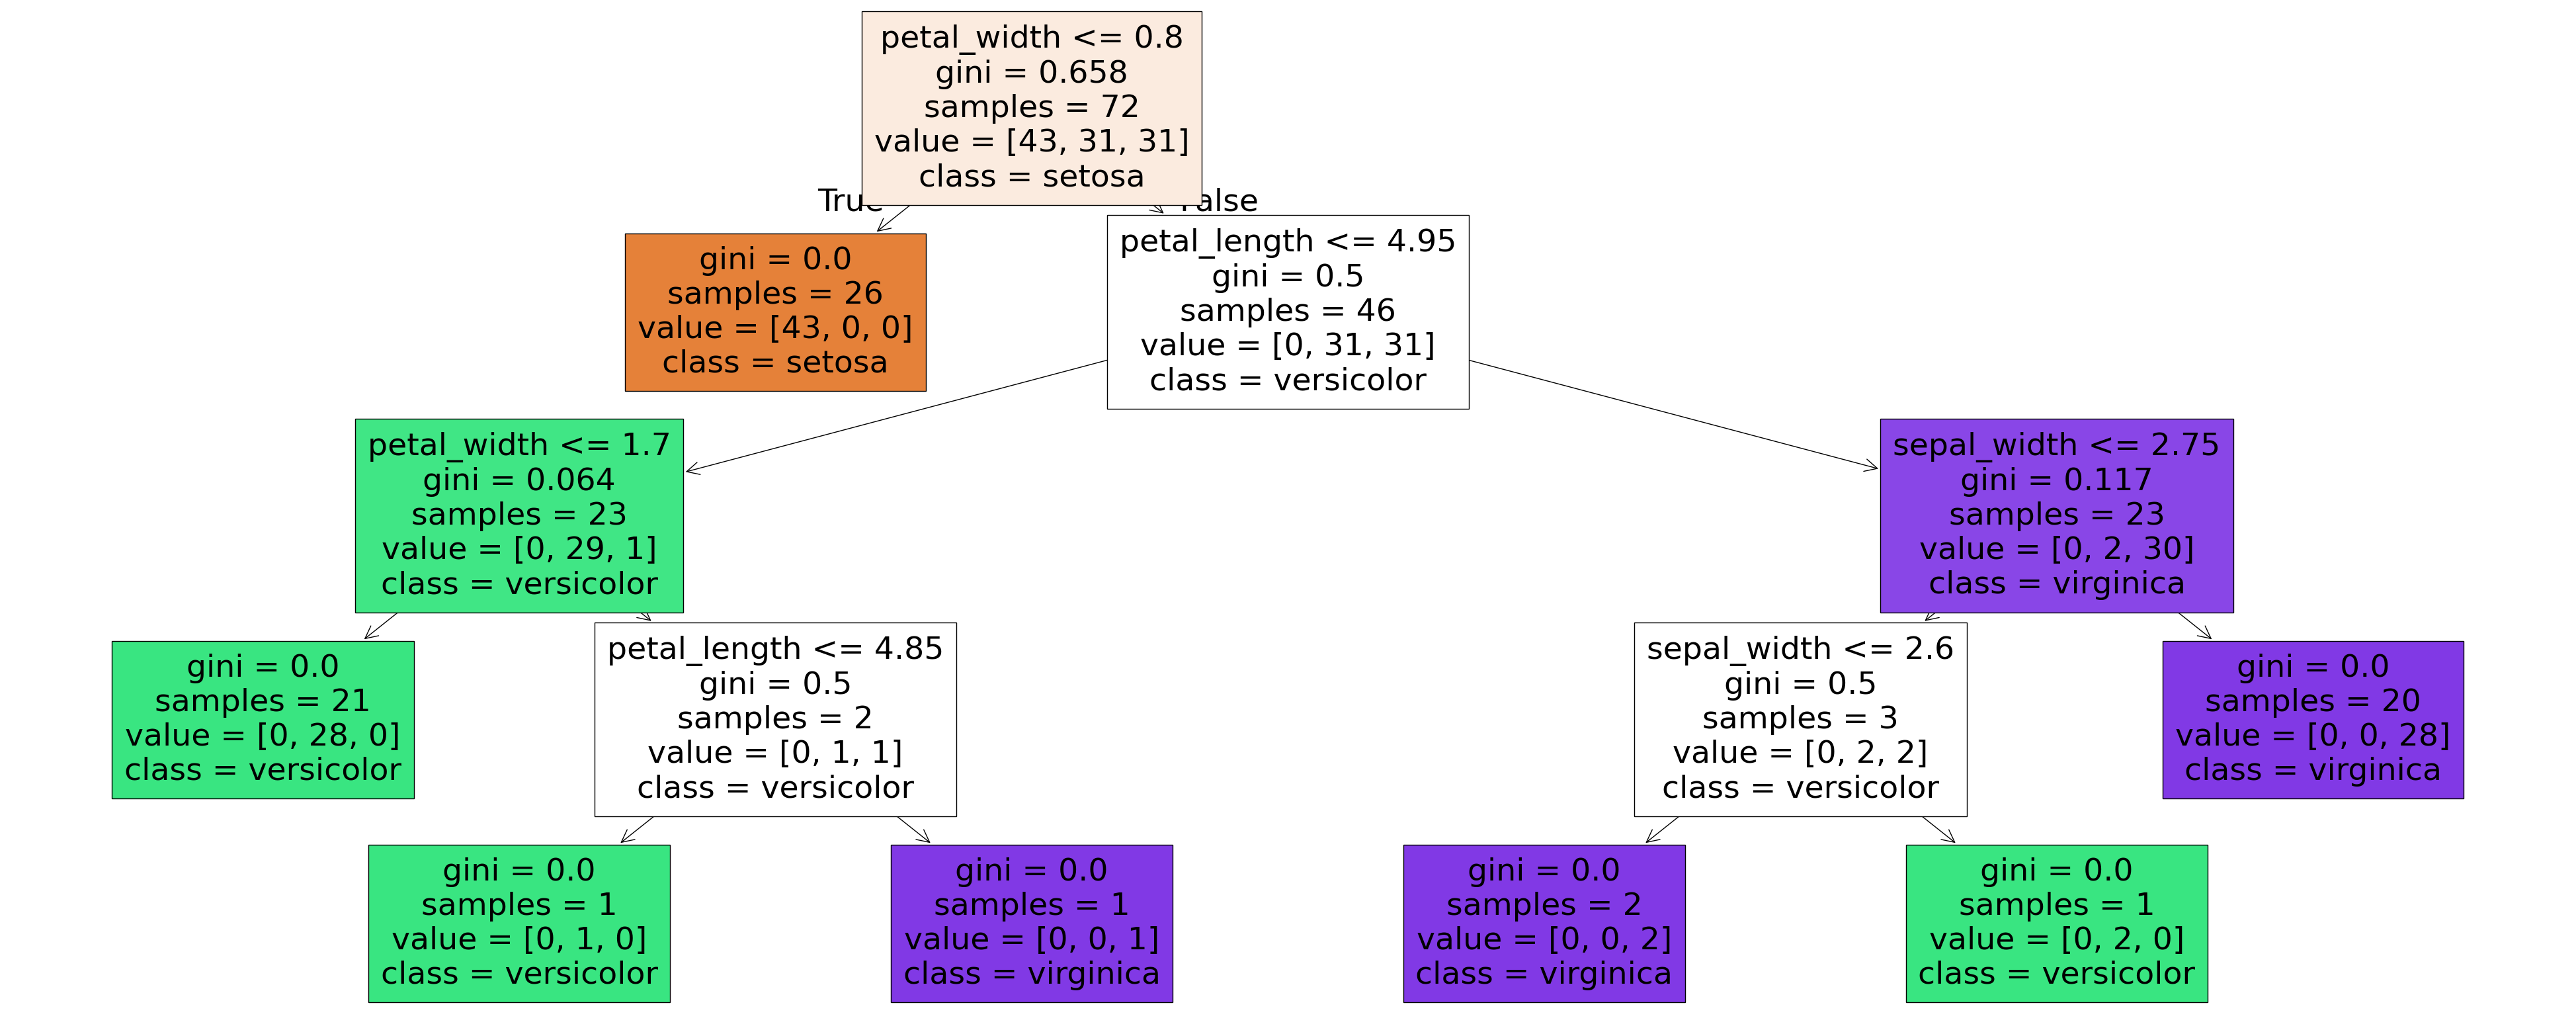

In [15]:
# 決定木の表示
plt.figure(figsize = (50, 20))
tree_rf = tree.plot_tree(rf_model.estimators_[0], filled=True, feature_names=features, class_names=targets)

In [16]:
# 各特徴量の重要度（分類への寄与の度合い）を計算
feature_importances = pd.DataFrame(rf_model.feature_importances_, index=X.columns, columns=["Weight"]).sort_values(by="Weight", ascending=False)
feature_importances

,Weight
petal_length,0.469953
petal_width,0.444625
sepal_length,0.062852
sepal_width,0.022570


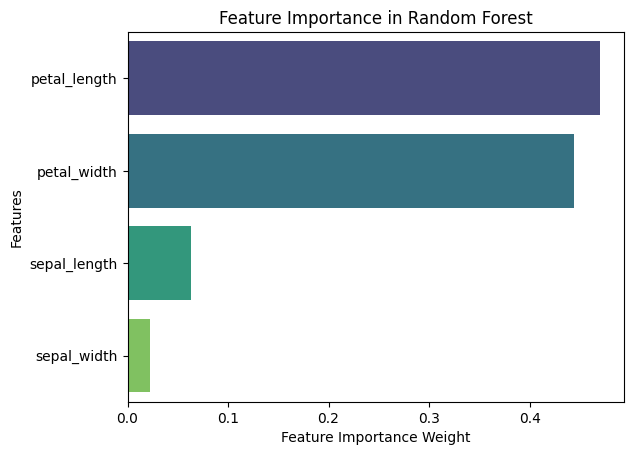

In [17]:
# 重要度を表示
sns.barplot(x="Weight", y=feature_importances.index, data=feature_importances, palette="viridis")
plt.xlabel("Feature Importance Weight")
plt.ylabel("Features")
plt.title("Feature Importance in Random Forest")
plt.show()